# Pipeline MLOps per il monitoraggio del sentiment sui social

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TCassano/sentiment-mlops/blob/main/notebooks/MLOps_Sentiment_Pipeline.ipynb)

**Repository GitHub:** [https://github.com/TCassano/sentiment-mlops](https://github.com/TCassano/sentiment-mlops)

Documento di review per il team Applied ML di MachineInnovators. Descrive il sistema costruito attorno al modello
pre-addestrato [`cardiffnlp/twitter-roberta-base-sentiment-latest`](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest):
servizio di inferenza, test, container, CI/CD, monitoraggio e ciclo di retraining. Spiega anche le scelte fatte.

Il notebook si può rieseguire: clona la repository, installa le dipendenze ed esegue sul codice reale i test, la valutazione
del modello, le analisi di drift e un giro completo degli step del DAG. Su Colab va bene il runtime CPU, ma con la GPU è più veloce.

### Indice
1. [Sintesi: requisiti → dove sono coperti](#1)
2. [Architettura](#2)
3. [Perché questa struttura](#3)
4. [Setup](#4)
5. [Servizio di inferenza (FastAPI)](#5)
6. [Valutazione del modello su dati pubblici](#6)
7. [Qualità del codice: test, lint, formatting](#7)
8. [Containerizzazione](#8)
9. [CI/CD con GitHub Actions](#9)
10. [Monitoraggio: metriche, dashboard, alert, drift](#10)
11. [Orchestrazione: DAG Airflow](#11)
12. [Limiti e cosa farei diversamente con più tempo](#12)

<a id="1"></a>
## 1. Sintesi: requisiti → dove sono coperti

| Requisito | Implementazione | File |
|---|---|---|
| Servizio di inferenza | FastAPI con `POST /predict`, `POST /predict/batch`, `GET /health`, `GET /metrics/` | `src/sentiment_service/main.py` |
| Modello | `twitter-roberta-base-sentiment-latest`, revisione fissabile con `MODEL_REVISION` e preprocessing come da model card | `src/sentiment_service/model.py` |
| Dati di prova | `tweet_eval/sentiment` (SemEval-2017), stesse 3 classi del modello | `src/sentiment_service/pipeline/data.py` |
| Ambiente riproducibile | venv + requisiti con versioni bloccate (torch CPU separato) e `pyproject.toml` | `requirements*.txt` |
| Storia dei commit | commit incrementali nell'ordine API → test → container → CI/CD → monitoraggio → orchestrazione → documentazione, stile Conventional Commits (`chore`, `feat`, `test`, `build`, `ci`, `docs`) | `git log` (cella di setup) |
| Test pytest | **41 test**: contratto API, comportamento del modello (stile CheckList), segnali di drift, logica della pipeline, giro completo del DAG, integrità del DAG | `tests/` |
| Linting e formatting | `ruff check` + `ruff format`, hook `pre-commit` | `pyproject.toml`, `.pre-commit-config.yaml` |
| Container | Dockerfile con torch CPU, pesi inclusi nell'immagine, utente non-root, `HEALTHCHECK` | `Dockerfile` |
| CI | lint, test veloci, test sul modello, controllo del DAG, build dell'immagine con smoke test, a ogni push | `.github/workflows/ci-cd.yml` |
| CD | push dell'immagine `ghcr.io/tcassano/sentiment-api` su GHCR (da `main` e dai tag `v*`) e deploy **opzionale** su una HuggingFace Docker Space | idem + `deploy/hf_space/` |
| Monitoraggio | Docker Compose con Prometheus e Grafana: dashboard di 16 pannelli, 7 regole di alert Prometheus e 2 alert Grafana | `docker-compose.yml`, `monitoring/` |
| Drift | segnali online (Prometheus) e offline (PSI, marcatori social, confidenza, macro-F1), con soglie verificate su 4 scenari reali | `pipeline/drift.py`, sezione 10 |
| Orchestrazione | DAG settimanale: raccolta → validazione → valutazione → drift → decisione → retraining → promozione → report | `airflow/dags/` |

<a id="2"></a>
## 2. Architettura

```
                    ┌─────────────────────────── GitHub ────────────────────────────┐
  git push ───────► │  Actions: lint ─ test ─ test-model ─ dag-check ─► docker build │
                    │                                   + smoke test ─► GHCR (main)  │
                    │                                               └─► HF Space (opz.)│
                    └────────────────────────────────────────────────────────────────┘
                                                   │ immagine
                                                   ▼
 post social ──► ┌──────────────────────┐  /metrics  ┌────────────┐      ┌──────────┐
  (client)  ───► │  FastAPI  (uvicorn)  │ ─────────► │ Prometheus │ ───► │ Grafana  │──► alert
                 │  RoBERTa sentiment   │  scrape 15s│  + rules   │      │ dashboard│
                 └──────────────────────┘            └────────────┘      └──────────┘
                            ▲  MODEL_NAME = modello promosso
                            │
 ┌───────────────────────── Airflow (settimanale) ───────────────────────────────────┐
 │ collect ─► validate ─► evaluate ─► drift ─► decide ─┬─► retrain ─► promote ──┐     │
 │                                                     └─► skip ───────────────┴─► report
 └────────────────────────────────────────────────────────────────────────────────────┘
```

Il servizio online e il ciclo offline condividono lo **stesso pacchetto Python** (`sentiment_service`). Preprocessing,
etichette e metriche sono definiti una volta sola, quindi non si crea differenza tra il modo in cui il modello viene valutato
e il modo in cui viene servito (*training/serving skew*).

<a id="3"></a>
## 3. Perché questa struttura

```
src/sentiment_service/        pacchetto installabile (src-layout)
├── main.py                   app FastAPI: factory create_app(), lifespan, middleware delle metriche
├── model.py                  wrapper HF, preprocessing, protocollo SentimentPredictor
├── schemas.py                contratti pydantic delle API
├── metrics.py                metriche Prometheus
├── config.py                 configurazione da variabili d'ambiente
└── pipeline/                 logica offline usata dal DAG
    ├── data.py  evaluation.py  drift.py  training.py  steps.py
tests/                        test_api · test_model · test_drift · test_pipeline · test_steps · test_dag
monitoring/                   prometheus/ (scrape + alert)  grafana/ (datasource, dashboard, alert)
airflow/dags/                 DAG che collega gli step, senza logica propria
scripts/                      evaluate.py (CLI), load_generator.py (traffico demo)
deploy/hf_space/              metadata della HuggingFace Space
```

Le scelte principali e il motivo di ciascuna:

- **src-layout + `pyproject.toml`.** Il codice si importa solo dopo l'installazione (`pip install -e .`), quindi i test girano
  sul pacchetto come verrà distribuito. API, Dockerfile e Airflow installano lo stesso pacchetto.
- **`create_app(settings, loader)` e protocollo `SentimentPredictor`.** L'API non sa da dove arriva il modello. Nei test si
  inietta un `FakePredictor` deterministico: la suite dell'API gira in circa 2 secondi senza scaricare 500 MB di pesi.
  Il modello vero ha test dedicati, marcati `@pytest.mark.model`.
- **Configurazione solo da variabili d'ambiente (12-factor).** Lo stesso artefatto gira in locale, in CI, in Compose e
  nella Space. Cambiare modello, ad esempio dopo una promozione, vuol dire cambiare `MODEL_NAME`, non il codice.
- **Logica della pipeline in Python puro, DAG ridotto al collegamento degli step.** Gli step si testano senza Airflow
  (`tests/test_steps.py` esegue l'intero ciclo con un modello finto). Si possono lanciare da notebook o da CLI e restano
  utilizzabili se un giorno si cambia orchestratore.
- **Soglie centralizzate e versionate.** `evaluation.Policy` e le costanti in `drift.py` stanno nel codice. Ogni modifica
  di una soglia passa da review e CI come qualsiasi altro cambiamento.
- **Errori del modello trattati come stato.** Se il caricamento fallisce, il processo resta su: `/health` risponde
  `degraded`, `/predict` risponde 503 e la metrica `sentiment_model_loaded` va a 0, che fa scattare l'alert. Si evita
  un crash-loop silenzioso.

<a id="4"></a>
## 4. Setup

Su **Colab** la cella clona la repository e installa le dipendenze mancanti. Colab ha già torch, transformers e numpy, e non
li declassiamo perché servirebbe riavviare il runtime. **In locale** si usa l'ambiente bloccato:

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements-torch-cpu.txt -r requirements-dev.txt && pip install -e . --no-deps
```

In [1]:
import os
import pathlib
import subprocess
import sys
import warnings

os.environ.update(HF_HUB_DISABLE_SYMLINKS_WARNING="1", HF_DATASETS_DISABLE_PROGRESS_BARS="1",
                  TRANSFORMERS_VERBOSITY="error")
warnings.filterwarnings("ignore", message="IProgress not found")

REPO_URL = "https://github.com/TCassano/sentiment-mlops"
IN_COLAB = "google.colab" in sys.modules


def sh(*cmd):
    """Esegue un comando e ne stampa l'output (funziona su Colab, Linux e Windows)."""
    r = subprocess.run(cmd, capture_output=True, text=True)
    print((r.stdout + r.stderr).strip())
    return r.returncode


if IN_COLAB:
    if not pathlib.Path("sentiment-mlops").exists():
        sh("git", "clone", "--depth", "20", REPO_URL)
    os.chdir("sentiment-mlops")
    sh(sys.executable, "-m", "pip", "install", "-q", "fastapi==0.115.6", "prometheus-client==0.21.1",
       "datasets", "pytest", "pytest-cov", "httpx", "ruff==0.8.4")
    sh(sys.executable, "-m", "pip", "install", "-q", "-e", ".", "--no-deps")
else:
    for candidate in (pathlib.Path("sentiment-mlops"), pathlib.Path("..")):
        if (candidate / "pyproject.toml").exists():
            os.chdir(candidate)
            break

REPO = pathlib.Path.cwd()
sys.path.insert(0, str(REPO / "src"))
print("Repository:", REPO.name, "\n")
_ = sh("git", "log", "--oneline", "-n", "12")

Repository: sentiment-mlops 

a5422bf feat: DAG Airflow settimanale con branch di retraining e verifica del DAG nel CI
24e1d88 feat: pipeline di raccolta, validazione, valutazione, drift e retraining con promozione su golden set
cafc632 feat: stack Docker Compose con Prometheus e Grafana, dashboard, alert e generatore di traffico
716e839 feat: metriche Prometheus e segnali di drift senza etichette nel servizio
1f37483 ci: pubblica l'immagine come sentiment-api su GHCR
233e56b ci: workflow GitHub Actions con lint, test, build e smoke test Docker, pubblicazione su GHCR e deploy opzionale su HF Spaces
6e429d8 build: Dockerfile con torch CPU, pesi inclusi, utente non-root e healthcheck
833c684 test: test di contratto dell'API e test comportamentali del modello
cb914d7 feat: servizio FastAPI con /predict, /predict/batch e /health, modello caricato nel lifespan
ac98282 chore: ambiente virtuale riproducibile, requisiti bloccati, ruff e pre-commit
77ff7cb Initial commit


<a id="5"></a>
## 5. Servizio di inferenza (FastAPI)

| Endpoint | Input | Output |
|---|---|---|
| `GET /health` | – | `status` (`ok`/`degraded`), `model_loaded`, `model`, `version` |
| `POST /predict` | `{"text": str}` (1–2000 caratteri, non vuoto) | `label`, `score` (probabilità della classe scelta), `scores` per classe |
| `POST /predict/batch` | `{"texts": [str]}` (1–64 elementi) | `model` + lista di predizioni nello stesso ordine |
| `GET /metrics/` | – | metriche in formato Prometheus |
| `GET /docs` | – | documentazione OpenAPI interattiva |

Dettagli implementativi:

- **Preprocessing come da model card.** Le menzioni diventano `@user` e i link diventano `http`. Il modello è stato
  addestrato così, e in più i nomi degli account non influenzano la predizione (lo verifica un test di invarianza).
- **Caricamento una sola volta nel `lifespan`** e inferenza a batch con `torch.no_grad()`. I testi oltre 128 token vengono
  troncati.
- **Validazione all'ingresso con pydantic.** Testi vuoti, solo spazi, troppo lunghi o batch troppo grandi ricevono 422,
  prima di occupare il modello.

Qui sotto l'app viene avviata in-process con `TestClient`, la stessa app servita da uvicorn nel container, con il modello reale.

In [2]:
import json
import time

import torch
import transformers

from sentiment_service.config import DEFAULT_MODEL
from sentiment_service.model import HFSentimentModel

t0 = time.perf_counter()
model = HFSentimentModel(DEFAULT_MODEL)
print(f"{DEFAULT_MODEL}\ncaricato in {time.perf_counter() - t0:.1f}s su {model.device} "
      f"| torch {torch.__version__} | transformers {transformers.__version__}")
print("Etichette:", model.labels)

cardiffnlp/twitter-roberta-base-sentiment-latest
caricato in 4.7s su cpu | torch 2.5.1+cpu | transformers 4.47.1
Etichette: ['negative', 'neutral', 'positive']


In [3]:
from fastapi.testclient import TestClient

from sentiment_service.main import create_app

client = TestClient(create_app(loader=lambda settings: model)).__enter__()  # esegue il lifespan

print("GET /health ->", client.get("/health").json())

r = client.post("/predict", json={"text": "@acme_support thanks, issue solved in 5 minutes! https://t.co/x"})
print("\nPOST /predict ->", r.status_code)
print(json.dumps(r.json(), indent=2))

batch = ["Worst customer service ever, 2 hours on hold #fail",
         "The store on Main Street opens at 9am tomorrow",
         "Honestly the best coffee in town ☕️"]
r = client.post("/predict/batch", json={"texts": batch})
print("\nPOST /predict/batch ->", r.status_code)
for p in r.json()["predictions"]:
    print(f"  {p['label']:>8}  {p['score']:.3f}  {p['text']}")

print("\nInput non valido -> ", client.post("/predict", json={"text": "   "}).status_code,
      client.post("/predict/batch", json={"texts": ["x"] * 65}).status_code)

GET /health -> {'status': 'ok', 'model_loaded': True, 'model': 'cardiffnlp/twitter-roberta-base-sentiment-latest', 'version': '0.1.0'}

POST /predict -> 200
{
  "text": "@acme_support thanks, issue solved in 5 minutes! https://t.co/x",
  "label": "positive",
  "score": 0.8685068488121033,
  "scores": {
    "negative": 0.014159499667584896,
    "neutral": 0.11733368784189224,
    "positive": 0.8685068488121033
  }
}

POST /predict/batch -> 200
  negative  0.957  Worst customer service ever, 2 hours on hold #fail
   neutral  0.902  The store on Main Street opens at 9am tomorrow
  positive  0.982  Honestly the best coffee in town ☕️

Input non valido ->  422 422


In [4]:
# Estratto di /metrics/ dopo le chiamate sopra: sono le serie che Prometheus raccoglie.
lines = client.get("/metrics/").text.splitlines()
keep = ("sentiment_predictions_total", "sentiment_http_requests_total", "sentiment_model_loaded",
        "sentiment_low_confidence", "sentiment_prediction_confidence_count", "sentiment_prediction_confidence_sum")
print("\n".join(line for line in lines if line.startswith(keep)))

sentiment_http_requests_total{endpoint="/health",method="GET",status="200"} 1.0
sentiment_http_requests_total{endpoint="/predict",method="POST",status="200"} 1.0
sentiment_http_requests_total{endpoint="/predict/batch",method="POST",status="200"} 1.0
sentiment_http_requests_total{endpoint="/predict",method="POST",status="422"} 1.0
sentiment_http_requests_total{endpoint="/predict/batch",method="POST",status="422"} 1.0
sentiment_predictions_total{label="positive"} 2.0
sentiment_predictions_total{label="negative"} 1.0
sentiment_predictions_total{label="neutral"} 1.0
sentiment_prediction_confidence_count 4.0
sentiment_prediction_confidence_sum 3.709340453147888
sentiment_low_confidence_predictions_total 0.0
sentiment_low_confidence_predictions_created 1.7938702749379609e+09
sentiment_model_loaded 1.0


<a id="6"></a>
## 6. Valutazione del modello su dati pubblici

Dataset: **`tweet_eval/sentiment`** (SemEval-2017 Task 4). Le classi sono le stesse del modello: 0 negativo, 1 neutro,
2 positivo. Usiamo un campione **stratificato** del test set, che mantiene le proporzioni tra le classi. Con
`EVAL_SAMPLE = None` si valuta l'intero test set (12.284 tweet; su CPU servono alcuni minuti).

La metrica principale è la **macro-F1**: le classi sono sbilanciate (circa metà dei tweet è neutra) e l'accuracy darebbe un
quadro troppo ottimista. Questa valutazione serve a fissare la **baseline** che il ciclo di retraining userà come
riferimento. Non cerchiamo di migliorare il modello.

In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

from sentiment_service.model import LABELS
from sentiment_service.pipeline.data import load_tweet_eval
from sentiment_service.pipeline.evaluation import evaluate

EVAL_SAMPLE = 3000
test_df = load_tweet_eval("test", sample=EVAL_SAMPLE)
print("Distribuzione delle etichette nel campione:", test_df.label.value_counts(normalize=True).round(3).to_dict())

t0 = time.perf_counter()
res = evaluate(model, test_df.text.tolist(), test_df.label.tolist())
elapsed = time.perf_counter() - t0

print(f"\nn={res['n']}  accuracy={res['accuracy']:.3f}  macro-F1={res['macro_f1']:.3f}")
print(f"throughput: {res['n'] / elapsed:.0f} testi/s su {model.device}  ({elapsed:.1f}s)\n")
print(classification_report(test_df.label, res["predictions"], labels=list(LABELS), digits=3))

Distribuzione delle etichette nel campione: {'neutral': 0.483, 'negative': 0.323, 'positive': 0.193}



n=3000  accuracy=0.728  macro-F1=0.728
throughput: 96 testi/s su cpu  (31.1s)

              precision    recall  f1-score   support

    negative      0.697     0.812     0.750       970
     neutral      0.761     0.672     0.714      1450
    positive      0.717     0.726     0.722       580

    accuracy                          0.728      3000
   macro avg      0.725     0.737     0.728      3000
weighted avg      0.732     0.728     0.727      3000



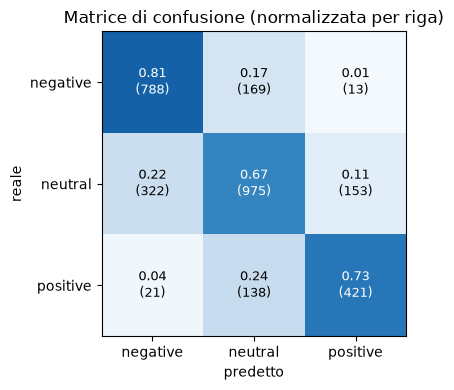

In [6]:
import matplotlib.pyplot as plt

cm = np.array(res["confusion_matrix"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=9)
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("predetto")
ax.set_ylabel("reale")
ax.set_title("Matrice di confusione (normalizzata per riga)")
plt.tight_layout()
plt.show()

In [7]:
# Analisi qualitativa: errori "gravi" (positivo <-> negativo), i più costosi per un report di brand reputation.
errors = test_df.assign(pred=res["predictions"])
severe = errors[((errors.label == "positive") & (errors.pred == "negative"))
                | ((errors.label == "negative") & (errors.pred == "positive"))]
print(f"Errori polari: {len(severe)} su {len(errors)} ({len(severe) / len(errors):.1%})\n")
with pd.option_context("display.max_colwidth", 110):
    print(severe.sample(6, random_state=0)[["label", "pred", "text"]].to_string(index=False))

Errori polari: 34 su 3000 (1.1%)

   label     pred                                                                                                                         text
negative positive                            Kim Fatty The Third will be pleased to know we've not been banned from nick naming him in the UK.
positive negative                                                          Don't really want this to end but here goes... — watching Westworld
positive negative     @user @user @user They come forward for chemical castration. If they don't and hurt a child it's death penalty. Easy :-)
positive negative                                                                Cuba's Fidel Castro, A Revolutionary Leader Who Defied The US
negative positive @user although it'd be extra nice is Maduro (president of Venezuela, where i live) could be included in that pack with Fidel
positive negative                                         I hope Donald trump builds a wall and says EA MADD

**Cosa ci dicono questi numeri**

- Il modello separa bene positivo e negativo: gli errori polari sono pochi. La maggior parte degli errori riguarda il
  **confine con la classe neutra**, come succede spesso con il sentiment a 3 classi. Molti tweet "neutri" dell'annotazione
  sono ambigui anche per una persona.
- Gli errori polari residui, come quelli sopra, vengono soprattutto da **ironia, sarcasmo e riferimenti politici o di
  attualità**, dove il sentiment dipende dal contesto più che dalle parole. Il retraining da solo non
  risolve questi casi: serve un controllo umano su un campione, descritto nella sezione 10.
- Per il monitoraggio interessa la **stabilità** del modello più dell'F1 assoluto: la macro-F1 misurata qui è il riferimento
  rispetto a cui il DAG misura i cali.

<a id="7"></a>
## 7. Qualità del codice: test, lint, formatting

| File | Cosa verifica | Modello |
|---|---|---|
| `test_api.py` | health, predict, batch (ordine preservato), validazione degli input (422), metriche esposte, stato `degraded` e 503 se il modello non si carica | finto |
| `test_model.py` | preprocessing; **test comportamentali stile CheckList**: *minimum functionality* su frasi ovvie, output come distribuzione di probabilità, **invarianza** a handle e URL, effetto **direzionale** della negazione, batch uguale a singolo | **reale** |
| `test_drift.py` | PSI (zero su distribuzioni identiche, alto su distribuzioni spostate), drift report, marcatori social su testi non social | – |
| `test_pipeline.py` | macro-F1 con modello finto, regole di retraining e promozione, validazione dei dati | finto |
| `test_steps.py` | **giro completo del DAG** senza Airflow: collect → validate → evaluate → drift → retrain → promote, con un candidato migliore che viene promosso nel registry | finto |
| `test_dag.py` | integrità del DAG: import senza errori, 9 task, branch corretto. Gira solo dove c'è Airflow, cioè nel job CI `dag-check` | – |

`ruff` fa sia da linter (pycodestyle, pyflakes, isort, bugbear, pyupgrade, simplify, naming) sia da formatter, quindi
basta un solo strumento. `pre-commit` esegue gli stessi controlli prima di ogni commit e la CI li ripete.

In [8]:
RUN_MODEL_TESTS = True  # i test sul modello reale riusano i pesi già in cache

print("$ ruff check ."); sh(sys.executable, "-m", "ruff", "check", ".")
print("\n$ ruff format --check ."); sh(sys.executable, "-m", "ruff", "format", "--check", ".")
print("\n$ pytest -m 'not model' --cov")
sh(sys.executable, "-m", "pytest", "-m", "not model", "-q", "-p", "no:warnings",
   "--cov=sentiment_service", "--cov-report=term")
if RUN_MODEL_TESTS:
    print("\n$ pytest -m model")
    sh(sys.executable, "-m", "pytest", "-m", "model", "-q", "-p", "no:warnings")

$ ruff check .
All checks passed!

$ ruff format --check .


24 files already formatted

$ pytest -m 'not model' --cov


.............s..................                                         [100%]

---------- coverage: platform win32, python 3.11.18-final-0 ----------
Name                                           Stmts   Miss  Cover
------------------------------------------------------------------
src\sentiment_service\__init__.py                  1      0   100%
src\sentiment_service\config.py                   16      0   100%
src\sentiment_service\main.py                     73      1    99%
src\sentiment_service\metrics.py                  22      1    95%
src\sentiment_service\model.py                    43     22    49%
src\sentiment_service\pipeline\__init__.py         0      0   100%
src\sentiment_service\pipeline\data.py            32      8    75%
src\sentiment_service\pipeline\drift.py           34      0   100%
src\sentiment_service\pipeline\evaluation.py      24      0   100%
src\sentiment_service\pipeline\steps.py           90      2    98%
src\sentiment_service\pipeline\training.py  

.........                                                                [100%]
9 passed, 32 deselected in 7.61s


La copertura bassa di `model.py` e `training.py` nella suite veloce è **voluta**: quel codice viene eseguito dai test
`-m model` (modello reale) e non ha senso coprirlo con un mock. Lo stesso vale per il download del dataset in `data.py`
(75%), sostituito da dati finti nei test. Il resto del pacchetto è coperto tra il 95% e il 100%.

<a id="8"></a>
## 8. Containerizzazione

```bash
docker build -t sentiment-api:local .
docker run --rm -p 8000:8000 sentiment-api:local       # http://localhost:8000/docs
curl -X POST localhost:8000/predict -H 'Content-Type: application/json' -d '{"text":"I love it"}'
```

| Scelta nel `Dockerfile` | Motivo |
|---|---|
| `python:3.11-slim` + **torch CPU** da `download.pytorch.org/whl/cpu` | immagine di circa 2,5 GB (misurata: 2,54 GB non compressa, di cui circa 0,5 GB di pesi) invece di oltre 6 GB con le wheel CUDA. Per un modello base su testi brevi la CPU basta |
| Requisiti copiati **prima** del codice | il layer con le dipendenze resta in cache e una modifica al codice ricostruisce l'immagine in pochi secondi |
| **Pesi inclusi nella build** (`PRELOAD_MODEL=1`) | niente download all'avvio, avvio veloce e prevedibile, e ogni immagine serve sempre gli stessi pesi. Si disattiva con `--build-arg PRELOAD_MODEL=0` |
| Utente **non-root** con uid 1000 | sicurezza; è anche l'uid richiesto da HuggingFace Spaces |
| `HEALTHCHECK` su `/health` | Docker e Compose sanno se il container è davvero pronto |
| `PORT` configurabile, `exec uvicorn` | la stessa immagine gira in locale e nella Space, e i segnali di stop arrivano al processo |

L'immagine viene costruita e verificata dalla CI a ogni push: il job `docker` avvia il container, aspetta che `/health`
riporti `model_loaded: true`, chiama `/predict` e legge `/metrics/`.

<a id="9"></a>
## 9. CI/CD con GitHub Actions

Un solo workflow (`.github/workflows/ci-cd.yml`), con i job in parallelo dove possibile:

```
push / PR ──► lint ──────────┐
          ├─► test ──────────┼──► docker: build + smoke test ──► [main|tag] push su GHCR ──► [main] deploy HF Space
          ├─► test-model ────┘
          └─► dag-check (Airflow 2.10 con i constraints ufficiali)
```

| Job | Trigger | Cosa fa |
|---|---|---|
| `lint` | ogni push e PR | `ruff check` (annotazioni inline nelle PR) + `ruff format --check` |
| `test` | ogni push e PR | suite veloce + report di coverage come artefatto |
| `test-model` | ogni push e PR | test comportamentali sul modello reale, con i pesi HF in cache tra un run e l'altro |
| `dag-check` | ogni push e PR | installa Airflow e verifica che il DAG si importi con la struttura attesa |
| `docker` | dopo lint e test | build con cache GHA, smoke test del container; su `main` e sui tag `v*` **pubblica** l'immagine su `ghcr.io/<owner>/sentiment-api` (tag: sha, branch, semver, latest) |
| `deploy-hf-space` | push su `main` | deploy opzionale su HuggingFace (sotto) |

**Deploy su HuggingFace Spaces.** Il job è già nel workflow e si attiva da solo quando la configurazione è presente; se manca,
il job termina con successo e lo segnala nel log:

1. su huggingface.co creare una Space con **SDK Docker**, ad esempio `<utente>/sentiment-api`;
2. creare un token con permesso *write* (Settings → Access Tokens);
3. su GitHub, in Settings → Secrets and variables → Actions, aggiungere il secret `HF_TOKEN` e la variabile `HF_SPACE_ID=<utente>/sentiment-api`.
   Il job usa l'environment `production`, a cui si possono aggiungere *required reviewers* per approvare il deploy a mano;
4. a ogni push su `main` il job assembla `Dockerfile`, `src/` e i requisiti con un `README.md` che contiene i metadata della Space
   (`sdk: docker`, `app_port: 8000`, in `deploy/hf_space/`) e li carica con `huggingface-cli upload`. La Space ricostruisce
   l'immagine e l'API risponde su `https://<utente>-sentiment-api.hf.space/docs`.

<a id="10"></a>
## 10. Monitoraggio: metriche, dashboard, alert, drift

```bash
docker compose up -d --build     # api :8000 · prometheus :9090 · grafana :3000 (admin/admin) · loadgen
```

Compose avvia API, Prometheus (raccoglie le metriche ogni 15s e valuta le regole di alert), Grafana (datasource, dashboard e
alert configurati da file, quindi nessun click manuale) e un **generatore di traffico** che invia post di esempio, così la
dashboard ha subito dei dati. Con `python scripts/load_generator.py --drift-after 200` il traffico passa a testi fuori dominio
e si vedono reagire i pannelli di drift.

### Metriche esposte

| Metrica | Tipo | A cosa serve |
|---|---|---|
| `sentiment_http_requests_total{endpoint,method,status}` | counter | traffico ed errori. Le etichette usano il template della route, quindi il numero di serie resta limitato |
| `sentiment_http_request_duration_seconds` | histogram | latenza p50/p95/p99 |
| `sentiment_model_loaded`, `sentiment_model_info{model_name}` | gauge | disponibilità e versione del modello servito |
| `sentiment_predictions_total{label}` | counter | **mix delle etichette predette** (drift delle predizioni, cambi di tono) |
| `sentiment_prediction_confidence` | histogram | distribuzione della confidenza (proxy di drift) |
| `sentiment_low_confidence_predictions_total` | counter | predizioni con confidenza < 0.5 |
| `sentiment_input_text_length_chars` | histogram | lunghezza degli input (data drift) |
| `sentiment_input_markers_total{marker}` | counter | testi con menzioni, link o hashtag: risponde alla domanda "è ancora traffico social?" (data drift) |

La **dashboard "Sentiment API"** ha due righe. *Service health*: modello up/down, richieste al secondo, tasso di 5xx,
latenza p95, predizioni nelle ultime 24h, richieste per endpoint e stato, percentili di latenza. *Sentiment & drift signals*:
quota di ciascuna etichetta, quota negativa nell'ultima ora contro la media dei 7 giorni, confidenza media, quota a bassa
confidenza con la linea di soglia, lunghezza degli input e heatmap della confidenza.

### Alert e soglie

| Alert | Condizione | Durata | Severità | Perché questa soglia |
|---|---|---|---|---|
| `SentimentApiDown` | `up == 0` oppure `model_loaded == 0` | 2m | critical | senza servizio non c'è monitoraggio del sentiment |
| `SentimentHighErrorRate` *(anche alert Grafana)* | 5xx > **5%** delle richieste (finestra 5m) | 5m | critical | in condizioni normali i 5xx sono vicini a 0. Il 5% filtra i casi isolati e coglie i guasti veri |
| `SentimentHighLatencyP95` | p95 di `/predict*` > **1s** | 10m | warning | su CPU una predizione singola richiede decine di ms. Oltre 1s significa saturazione o batch anomali |
| `SentimentLowConfidenceShare` *(anche alert Grafana)* | quota con confidenza < 0.5 > **15%** (finestra 1h) | 30m | warning | sui dati di riferimento la quota è circa **4%** (misurata sotto), quindi 15% è circa 4 volte la baseline. È un segnale di guasto grave, non un rivelatore fine di drift: gli esperimenti sotto mostrano che la confidenza reagisce poco al cambio di dominio |
| `SentimentSocialMarkerShift` | quota di testi con menzioni, link o hashtag che si sposta di oltre **15 punti** rispetto alla media dei 7 giorni | 1h | warning | è il segnale di data drift più discriminante tra quelli misurati: con testi non social la quota di menzioni passa dal 30% a 0 |
| `SentimentNegativeShareSpike` | quota negativa nell'ultima ora > **1,5 volte** la media dei 7 giorni, con almeno 100 predizioni | 15m | warning | il segnale **di business**: il tono del pubblico sta cambiando. È ciò che oggi il presidio manuale scopre solo a fine mese |
| `SentimentInputLengthShift` | mediana della lunghezza nell'ultima ora > 2 volte quella dei 7 giorni | 1h | info | nuova sorgente o nuovo formato in arrivo, ad esempio recensioni lunghe al posto dei tweet |

### Come accorgersi di data drift e concept drift

In produzione **le etichette vere non arrivano in tempo reale**, quindi i segnali sono a due livelli.

**Data drift** (cambia la distribuzione di P(x): arrivano testi diversi da quelli visti in addestramento):
- **lunghezza dei testi**: PSI rispetto alla finestra di riferimento, con soglia **0,2** (soglia standard: sotto 0,1 stabile,
  tra 0,1 e 0,2 da osservare, sopra 0,2 cambiamento significativo);
- **marcatori social**: quota di testi con menzioni, link o hashtag. Si interviene se una quota si sposta di oltre **15 punti**:
  segnala una nuova sorgente, un nuovo formato o un nuovo uso della piattaforma;
- **confidenza del modello**: calo della confidenza media oltre **5 punti**. È utile come conferma, ma gli esperimenti sotto
  mostrano che da solo è debole: il modello rimane sicuro di sé anche su testi di un altro dominio.

*Un segnale scartato.* Avevo previsto anche il **tasso di parole mai viste (OOV)** rispetto al vocabolario di riferimento. Misurato
sui dati, vale circa il 30% in *tutti* gli scenari, compreso quello stabile, perché il vocabolario dei tweet ha una coda lunghissima.
Non distingue nulla e l'ho tolto. È il motivo per cui le soglie vanno verificate sui dati prima di metterle in produzione.

**Prediction drift** (cambia P(ŷ)): PSI sulla distribuzione delle etichette predette, con soglia **0,2**. Da solo può anche essere
un **cambio reale del tono**: è proprio l'informazione che il cliente vuole avere. Lo si distingue da un problema del modello
guardando insieme gli altri segnali: un tono che cambia con confidenza stabile è un fenomeno reale, un mix che cambia con
confidenza in calo fa pensare a un problema del modello.

**Concept drift** (cambia P(y|x): lo stesso testo andrebbe classificato in modo diverso, ad esempio per un nuovo meme ironico
o per una parola che cambia connotazione dopo una crisi). Non si vede dagli input, **serve ground truth**. Il DAG etichetta
ogni settimana un campione casuale (ad esempio 300–500 post, annotati da persone) e misura la **macro-F1**. Si interviene se
scende sotto **0,65** oppure se cala di più di **0,05** rispetto alla baseline. Un ulteriore segnale è il disaccordo tra modello
e annotatori, classe per classe.

La cella seguente esegue `drift_report` (lo stesso codice usato dal DAG) su quattro scenari, confrontati con una finestra
di riferimento di 1000 tweet del validation set di `tweet_eval`:
1. **Stabile**: tweet del train set, stessa distribuzione del riferimento. Qui *non* deve scattare nulla;
2. **Cambio di tono**: solo tweet negativi, a simulare un'ondata di critiche su un brand;
3. **Cambio di dominio**: recensioni di film (`rotten_tomatoes`), un tipo di testo diverso dai tweet;
4. **Drift temporale reale**: il test set di `tweet_eval` viene da SemEval-2017, un periodo e una raccolta diversi da
   train e validation. È un caso di drift che esiste davvero in un dataset pubblico, non una simulazione.

In [9]:
from datasets import load_dataset

from sentiment_service.pipeline import drift


def window(texts):
    preds = model.predict(list(texts))
    return list(texts), [p.label for p in preds], [p.score for p in preds]


ref = window(load_tweet_eval("validation", sample=1000).text)
train_df = load_tweet_eval("train", sample=8000, seed=1)
reviews = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="test").to_pandas()
scenarios = {
    "1. stabile": window(train_df.text.sample(1000, random_state=1)),
    "2. cambio di tono": window(train_df[train_df.label == "negative"].text.sample(600, random_state=1)),
    "3. cambio di dominio": window(reviews.text.sample(1000, random_state=1)),
    "4. drift temporale": window(test_df.text.sample(1000, random_state=1)),
}
reports = {name: drift.drift_report(*ref, *cur) for name, cur in scenarios.items()}

print(f"Riferimento: confidenza media {np.mean(ref[2]):.3f} | quota con confidenza < 0.5: "
      f"{np.mean(np.array(ref[2]) < 0.5):.1%} | marcatori {drift.marker_shares(ref[0])}")
print(f"Soglie: PSI > {drift.PSI_ALERT} | marker_shift > {drift.MARKER_SHIFT_ALERT} "
      f"| calo di confidenza > {drift.CONFIDENCE_DROP_ALERT}\n")
cols = ["text_length_psi", "marker_shift", "label_psi", "confidence_drop", "data_drift", "prediction_drift",
        "drift_detected"]
table = pd.DataFrame(reports).T[cols]
table.insert(4, "low_conf_share", [np.mean(np.array(c[2]) < 0.5) for c in scenarios.values()])
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
    display(table) if "display" in globals() else print(table)

Riferimento: confidenza media 0.779 | quota con confidenza < 0.5: 4.0% | marcatori {'mention': 0.299, 'url': 0.001, 'hashtag': 0.181}
Soglie: PSI > 0.2 | marker_shift > 0.15 | calo di confidenza > 0.05

                     text_length_psi marker_shift label_psi confidence_drop  low_conf_share data_drift prediction_drift drift_detected
1. stabile                     0.032        0.012     0.004           0.001           0.044      False            False          False
2. cambio di tono              0.071        0.018     2.081           0.042           0.052      False             True           True
3. cambio di dominio           0.604        0.299     0.281           0.028           0.058       True             True           True
4. drift temporale             0.356        0.187     0.230           0.006           0.025       True             True           True


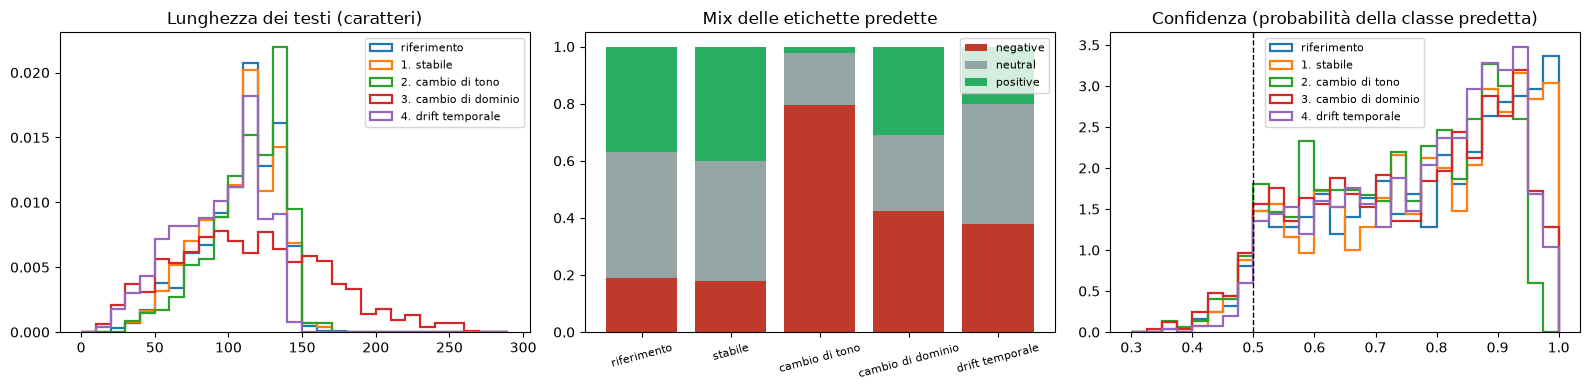

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
names = ["riferimento", *scenarios]
windows = [ref, *scenarios.values()]

for name, (texts, _, _) in zip(names, windows):
    axes[0].hist([len(t) for t in texts], bins=np.arange(0, 300, 10), histtype="step", lw=1.6, density=True, label=name)
axes[0].set_title("Lunghezza dei testi (caratteri)")
axes[0].legend(fontsize=8)

shares = np.array([[np.mean(np.array(p) == lab) for lab in LABELS] for _, p, _ in windows])
x = np.arange(len(names))
bottom = np.zeros(len(names))
for k, lab in enumerate(LABELS):
    axes[1].bar(x, shares[:, k], bottom=bottom, label=lab, color=["#c0392b", "#95a5a6", "#27ae60"][k])
    bottom += shares[:, k]
axes[1].set_xticks(x, [n.split(". ")[-1] for n in names], rotation=15, fontsize=8)
axes[1].set_title("Mix delle etichette predette")
axes[1].legend(fontsize=8)

for name, (_, _, conf) in zip(names, windows):
    axes[2].hist(conf, bins=np.linspace(0.3, 1, 29), histtype="step", lw=1.6, density=True, label=name)
axes[2].axvline(0.5, ls="--", c="k", lw=1)
axes[2].set_title("Confidenza (probabilità della classe predetta)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lettura dei risultati**

- **Stabile**: tutti gli indicatori sono molto sotto soglia e non scatta nessun allarme. È importante, perché un monitoraggio
  che genera falsi positivi finisce presto per essere ignorato.
- **Cambio di tono**: scatta solo il **prediction drift** (PSI sulle etichette molto alto), mentre lunghezza e marcatori restano
  normali. È il pattern di un **cambio reale del sentiment**, da segnalare al cliente e non da "correggere" con un retraining.
  Online corrisponde all'alert `SentimentNegativeShareSpike`.
- **Cambio di dominio**: scatta il **data drift** con entrambi i segnali, lunghezza e marcatori (le menzioni passano dal 30% a 0).
  Il modello lavora fuori dalla distribuzione per cui è stato addestrato, quindi serve una valutazione con etichette prima di
  fidarsi dei numeri.
- **Drift temporale**: il test set SemEval-2017 è davvero diverso da train e validation. Ha più menzioni e hashtag (37% di
  tweet con hashtag contro 18%), una distribuzione di lunghezze diversa e circa il doppio dei tweet negativi. Il report lo rileva su lunghezza, marcatori e mix delle etichette (la confidenza invece non si muove), mentre la macro-F1 (sezione 6, 0,73 contro 0,75
  del riferimento) cala di poco e resta sotto la soglia di retraining. È la situazione più comune in produzione: **gli input
  cambiano prima che le prestazioni crollino**, e questo dà il tempo di raccogliere etichette.
- **La confidenza è il segnale più debole.** Anche sulle recensioni di film cala solo di 2–3 punti, sotto la soglia di 5, e la
  quota a bassa confidenza resta in cifre singole. Un transformer fuori dominio tende a restare sicuro di sé. Per questo
  l'alert sulla confidenza è tarato su guasti grossi (15%), e il drift viene rilevato sugli input.

<a id="11"></a>
## 11. Orchestrazione: DAG Airflow

`airflow/dags/sentiment_retraining_dag.py`: DAG `sentiment_monitoring_retraining`, con esecuzione **settimanale**
(`@weekly`), `catchup=False`, un solo run attivo alla volta, 1 retry per task e timeout di 3h sul retraining.

```
collect_data ─► validate_data ─► evaluate_current_model ─► check_drift ─► decide (branch)
                                                                           ├─► retrain_model ─► evaluate_and_promote ─┐
                                                                           └─► skip_retraining ───────────────────────┴─► publish_report
```

| Task | Cosa fa | Note per la produzione |
|---|---|---|
| `collect_data` | raccoglie i post del periodo con un campione etichettato e li scrive in parquet | qui si campiona da `tweet_eval/train`. In produzione: API social o data lake, più annotazione umana di un campione |
| `validate_data` | controlli di qualità: righe minime, colonne, testi vuoti, etichette valide | **interrompe il run** se i dati sono sbagliati, prima che arrivino all'addestramento |
| `evaluate_current_model` | macro-F1 e accuracy del modello in produzione sul nuovo batch; salva predizioni e confidenze | segnale di **concept drift** |
| `check_drift` | `drift_report` rispetto alla finestra di riferimento: PSI di lunghezza ed etichette, quota di marcatori social, calo di confidenza | segnale di **data drift** e **prediction drift** |
| `decide` | `needs_retraining`: F1 < 0,65, oppure calo > 0,05 rispetto alla baseline, oppure drift | branch Airflow |
| `retrain_model` | fine-tuning del modello corrente sui nuovi dati etichettati (training loop PyTorch minimale) | su un worker con GPU |
| `evaluate_and_promote` | confronta candidato e modello corrente su un **golden set fisso** e promuove solo se il candidato guadagna almeno **0,01** di macro-F1 | la promozione aggiorna il registry (`models/registry/current.json`), poi la CD costruisce l'immagine con il nuovo `MODEL_NAME` |
| `publish_report` | report JSON del run (valutazione, drift, decisione) | `trigger_rule=none_failed_min_one_success`: gira in entrambi i rami |

Il **golden set fisso** è necessario: confrontare candidato e modello corrente sui dati appena raccolti, gli stessi usati per
addestrare il candidato, darebbe un vantaggio artificiale al candidato.

Sotto si eseguono **gli stessi step del DAG** in sequenza, con il modello reale, senza Airflow. Con `RUN_RETRAIN = True` si
esegue anche il ramo di retraining e promozione, anche quando `decide` non lo richiederebbe, per mostrare il gate al lavoro.
Su CPU servono alcuni minuti; con `False` il ramo segue la decisione del DAG.

In [11]:
import shutil

from sentiment_service.pipeline import steps

for d in ("data", "models", "reports"):
    shutil.rmtree(REPO / d, ignore_errors=True)  # run riproducibile da zero
os.environ.update(PIPELINE_DATA_DIR=str(REPO / "data"), PIPELINE_MODELS_DIR=str(REPO / "models"),
                  PIPELINE_REPORTS_DIR=str(REPO / "reports"))
# Riusa i pesi già in memoria invece di ricaricarli a ogni step (nel DAG ogni task è un processo separato).
steps._load = lambda name: model if name == DEFAULT_MODEL else HFSentimentModel(name)

RUN_RETRAIN = True  # forza il ramo retrain -> promote a scopo dimostrativo
run_id = "20261026"

batch = steps.validate(steps.collect(run_id, sample=500))
print("1-2. collect + validate ->", pathlib.Path(batch).relative_to(REPO))
reference = steps.ensure_reference()
print("     reference           ->", reference)
evaluated = steps.evaluate_current(batch, run_id)
print("3.   evaluate            ->", {k: round(v, 3) if isinstance(v, float) else v for k, v in evaluated.items()
                                      if k != "predictions_path"})
drift_res = steps.check_drift(evaluated["predictions_path"])
print("4.   check_drift         ->", {k: round(v, 3) if isinstance(v, float) else v for k, v in drift_res.items()})
decision = steps.decide(evaluated, drift_res)
print("5.   decide              ->", decision)

promotion = None
if decision["retrain"] or RUN_RETRAIN:
    t0 = time.perf_counter()
    candidate = steps.retrain(batch, run_id)
    promotion = steps.promote_or_reject(candidate, run_id)
    print(f"6.   retrain + promote   -> ({time.perf_counter() - t0:.0f}s)",
          {**promotion, "candidate": pathlib.Path(promotion["candidate"]).relative_to(REPO).as_posix()})
    print("     modello in produzione dopo il run:", steps.current_model())
else:
    print("6.   skip_retraining     -> modello in salute e nessun drift: niente retraining")

report = steps.write_report(run_id, evaluation=evaluated, drift=drift_res, decision=decision, promotion=promotion)
print("7.   publish_report      ->", pathlib.Path(report).relative_to(REPO))

1-2. collect + validate -> data\raw\batch_20261026.parquet


     reference           -> {'model': 'cardiffnlp/twitter-roberta-base-sentiment-latest', 'macro_f1': 0.752541033081156, 'n': 1000}


3.   evaluate            -> {'model': 'cardiffnlp/twitter-roberta-base-sentiment-latest', 'n': 501, 'accuracy': 0.766, 'macro_f1': 0.758}
4.   check_drift         -> {'text_length_psi': 0.056, 'marker_shift': 0.038, 'label_psi': 0.001, 'mean_confidence_ref': 0.779, 'mean_confidence_cur': 0.779, 'confidence_drop': 0.0, 'data_drift': False, 'prediction_drift': False, 'drift_detected': False}
5.   decide              -> {'retrain': False, 'reasons': []}


6.   retrain + promote   -> (56s) {'candidate': 'models/candidates/20261026', 'candidate_f1': 0.6909041384346054, 'current_f1': 0.725074925074925, 'promoted': False}
     modello in produzione dopo il run: cardiffnlp/twitter-roberta-base-sentiment-latest
7.   publish_report      -> reports\run_20261026.json


**Cosa è successo in questo run**

- Con dati dello stesso dominio, `decide` sceglie correttamente di **non** riaddestrare: la macro-F1 è in linea con la
  baseline e non c'è drift.
- Il ramo di retraining, forzato a scopo dimostrativo, produce un candidato **peggiore** del modello in produzione sul golden
  set. Un fine-tuning di una sola epoca su 500 esempi altera un modello addestrato su circa 124 milioni di tweet e gli fa perdere
  parte di ciò che sapeva (*catastrophic forgetting*). Il gate lo **scarta** e il registry continua a puntare al modello originale.
  È il caso che il gate esiste per bloccare: **un retraining automatico non deve mai poter peggiorare la produzione**.
- In `tests/test_steps.py` è coperto anche il caso opposto: un candidato migliore viene promosso e il registry si aggiorna.
- Per un retraining utile servirebbero più dati etichettati del dominio del cliente, un learning rate più basso o il congelamento
  degli strati inferiori, e un mix di dati nuovi e vecchi (*replay*). Sono tutti parametri di `fine_tune`.

**Avvio in Airflow** (Linux o WSL):

```bash
pip install "apache-airflow==2.10.4" --constraint \
  https://raw.githubusercontent.com/apache/airflow/constraints-2.10.4/constraints-3.11.txt
pip install -r requirements-torch-cpu.txt -r requirements-dev.txt && pip install .
export AIRFLOW__CORE__DAGS_FOLDER=$PWD/airflow/dags PIPELINE_DATA_DIR=/data PIPELINE_MODELS_DIR=/models
airflow standalone          # UI su :8080 → DAG "sentiment_monitoring_retraining" → Trigger
```

<a id="12"></a>
## 12. Limiti e cosa farei diversamente con più tempo

**Limiti di questa consegna**
- Il **DAG** è verificato nel CI (job `dag-check`: import senza errori, 9 task, branch corretto) e i suoi step sono eseguiti in sequenza in questo notebook e in `tests/test_steps.py`. Non l'ho fatto girare end-to-end dentro uno scheduler Airflow, che su Windows richiede WSL o Docker.
- Il **deploy su HuggingFace Spaces** è pronto nel workflow ma non attivato (nessun `HF_TOKEN` configurato): la CD effettiva è la pubblicazione dell'immagine su GHCR.
- La **raccolta dati** è simulata campionando `tweet_eval`; le soglie sono tarate su dataset pubblici, non sul traffico reale di un cliente.
- Il **retraining** è dimostrativo: una sola epoca su CPU, su 500 esempi.

**Cosa farei diversamente con più tempo**

**Modello e dati**
- **Registry vero (MLflow o HF Hub con tag e revisioni)** al posto del file `current.json`, con lineage completo
  (dati, codice e iperparametri di ogni modello) e un rollback con un click.
- **Annotazione umana strutturata**: coda di etichettatura (Label Studio, Argilla) alimentata in modo mirato dalle predizioni
  a bassa confidenza (*active learning*), con misura dell'accordo tra annotatori.
- **Dominio e lingue dei clienti**: valutare su post reali e in italiano. Il modello è addestrato su tweet in inglese: per
  testi italiani valuterei `cardiffnlp/twitter-xlm-roberta-base-sentiment` o un fine-tuning dedicato.
- Analisi per **aspetto ed entità**: il sentiment verso il brand, non verso il testo nel suo complesso.

**Servizio**
- **Ottimizzazione dell'inferenza**: export ONNX o quantizzazione int8, dynamic batching e più worker, misurati con un load
  test (Locust o k6) per definire SLO veri al posto delle soglie stimate.
- **Autenticazione** (API key o OAuth), rate limiting, log strutturati JSON con request id, tracing OpenTelemetry.
- **Logging delle predizioni** (testo con hash e anonimizzato, etichetta, confidenza) su uno storage analitico, così il drift
  si calcola sul traffico reale e non solo su campioni. Va fatto in modo compatibile con il GDPR (minimizzazione dei dati, retention).

**Monitoraggio**
- Drift **semantico sugli embedding** del modello (MMD o classificatore di dominio) al posto dell'OOV a livello di parola, che
  si è rivelato inutilizzabile sui tweet; report Evidently pubblicati dal DAG.
- **Soglie tarate sul traffico storico**, ad esempio come percentili della distribuzione settimana su settimana, invece che fissate
  a priori o su dataset pubblici come qui.
- **Alertmanager** con routing su Slack o email e silenziamento; metriche e dashboard **per cliente**.

**Delivery**
- Ambienti **staging e produzione** con promozione manuale; rilascio **canary** o **shadow** del modello candidato prima
  dello switch, confrontando online le distribuzioni di predizione e confidenza.
- Gestione delle dipendenze con lock file (`uv` o `pip-tools` con hash), scansione di sicurezza dell'immagine (Trivy),
  SBOM, Dependabot.
- Airflow in Docker Compose o Kubernetes, con task containerizzati (`KubernetesPodOperator`) e GPU on-demand per il retraining.



---
*Notebook generato ed eseguito sul codice della repository: ogni numero mostrato viene dalle celle qui sopra.*
